# ML CIE 2 – Activity 2
## Simple House Price Prediction Using Linear Regression

### Objective
To develop a Simple Linear Regression model to predict house prices using house area as an input feature. The model will be trained and evaluated using a training and testing dataset, and its performance will be measured using MAE, MSE, RMSE, and R² Score.

### Dataset
Bengaluru House Price Dataset

### Input Feature
Total Area (Square Feet)

### Target Variable
House Price (Lakhs)

## Step 1: Dataset Selection and Understanding

**Dataset Name:** Bengaluru House Price Dataset

**Source:** Kaggle – https://www.kaggle.com/datasets/amitabhajoy/bengaluru-house-price-data

**Description:** This dataset contains information about residential properties in Bengaluru, India. It includes features such as area type, location, number of bedrooms, total square feet, bathrooms, and property price.

**Input Feature (X):** total_sqft

**Target Variable (y):** price

**Reason for Selection:** The total area of a property may influence its selling price. Therefore, total_sqft is selected as the input feature to predict the continuous numerical target price.

**Model:** Simple Linear Regression.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Bengaluru_House_Data.csv")

df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (13320, 9)

Column Names:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']

Data Types:
area_type        object
availability     object
location         object
size             object
society          object
total_sqft       object
bath            float64
balcony         float64
price           float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: fl

In [ ]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df)) * 100)

Missing Values:
area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

Missing Value Percentage:
area_type        0.000000
availability     0.000000
location         0.007508
size             0.120120
society         41.306306
total_sqft       0.000000
bath             0.548048
balcony          4.572072
price            0.000000
dtype: float64


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 529


## Step 2: Loading and Inspecting the Dataset

The Bengaluru House Data CSV file was loaded into a Pandas DataFrame using the read_csv() function. The dataset contains 13,320 rows and 9 columns.

The dataset includes both numerical and categorical features. The price column is numerical and represents the property price in lakhs. The total_sqft column is stored as an object data type and requires further inspection before it can be used in a regression model.

The dataset was inspected using head(), shape, info(), describe(), missing-value analysis, and duplicate checking.


In [ ]:
# Display some unique values from total_sqft
df['total_sqft'].unique()[:30]

array(['1056', '2600', '1440', '1521', '1200', '1170', '2732', '3300',
       '1310', '1020', '1800', '2785', '1000', '1100', '2250', '1175',
       '1180', '1540', '2770', '600', '1755', '2800', '1767', '510',
       '1250', '660', '1610', '1151', '1025', '2100 - 2850'], dtype=object)

In [ ]:
# Find values that are not simple numbers
sqft_values = df['total_sqft'].astype(str)

non_numeric_sqft = sqft_values[
    ~sqft_values.str.match(r'^\d+(\.\d+)?$')
]

print("Number of unusual total_sqft values:", len(non_numeric_sqft))

print("\nExamples:")
print(non_numeric_sqft.head(20))

Number of unusual total_sqft values: 247

Examples:
30        2100 - 2850
56        3010 - 3410
81        2957 - 3450
122       3067 - 8156
137       1042 - 1105
165       1145 - 1340
188       1015 - 1540
224       1520 - 1740
410    34.46Sq. Meter
549       1195 - 1440
579       1200 - 2400
648         4125Perch
661       1120 - 1145
669       4400 - 6640
672       3090 - 5002
702       4400 - 6800
772       1160 - 1195
775     1000Sq. Meter
801       4000 - 5249
850       1115 - 1130
Name: total_sqft, dtype: object


In [ ]:
import re
import numpy as np

def convert_sqft(value):
    value = str(value).strip().lower()

    # Handle ranges such as "2100 - 2850"
    range_match = re.match(r'^([\d.]+)\s*-\s*([\d.]+)$', value)

    if range_match:
        lower = float(range_match.group(1))
        upper = float(range_match.group(2))
        return (lower + upper) / 2

    # Extract the numerical value
    number_match = re.search(r'[\d.]+', value)

    if not number_match:
        return np.nan

    number = float(number_match.group())

    # Convert different units into square feet
    if 'sq. meter' in value or 'sq meter' in value:
        return number * 10.7639

    elif 'sq. yards' in value or 'sq yards' in value:
        return number * 9

    elif 'acre' in value:
        return number * 43560

    elif 'perch' in value:
        return number * 272.25

    elif 'cent' in value:
        return number * 435.6

    elif 'guntha' in value or 'guntha' in value:
        return number * 1089

    elif 'grounds' in value or 'ground' in value:
        return number * 2400

    else:
        # Normal numeric values are already in square feet
        return number


# Convert total_sqft to numerical square feet
df['total_sqft_clean'] = df['total_sqft'].apply(convert_sqft)

# Display the original and converted values
display(df[['total_sqft', 'total_sqft_clean']].head(20))

,total_sqft,total_sqft_clean
0,1056,1056.0
1,2600,2600.0
2,1440,1440.0
3,1521,1521.0
4,1200,1200.0
5,1170,1170.0
6,2732,2732.0
7,3300,3300.0
8,1310,1310.0
9,1020,1020.0


In [ ]:
print("Missing values after conversion:",
      df['total_sqft_clean'].isnull().sum())

print("\nConverted column data type:",
      df['total_sqft_clean'].dtype)

print("\nSummary statistics:")
print(df['total_sqft_clean'].describe())

print("\nRemaining unconverted values:")
display(df[df['total_sqft_clean'].isnull()][['total_sqft']])

Missing values after conversion: 0

Converted column data type: float64

Summary statistics:
count    1.332000e+04
mean     1.911597e+03
std      1.727690e+04
min      1.000000e+00
25%      1.100000e+03
50%      1.277250e+03
75%      1.680000e+03
max      1.306800e+06
Name: total_sqft_clean, dtype: float64

Remaining unconverted values:


,total_sqft


In [ ]:
# Smallest area values
print("Smallest area values:")
display(
    df.sort_values('total_sqft_clean')[
        ['total_sqft', 'total_sqft_clean', 'price', 'location']
    ].head(15)
)

# Largest area values
print("\nLargest area values:")
display(
    df.sort_values('total_sqft_clean', ascending=False)[
        ['total_sqft', 'total_sqft_clean', 'price', 'location']
    ].head(15)
)

Smallest area values:


,total_sqft,total_sqft_clean,price,location
4086,1,1.0000,120.00,Sarjapur Road
4972,5,5.0000,115.00,Srirampuram
349,11,11.0000,74.00,Suragajakkanahalli
1020,15,15.0000,30.00,Weavers Colony
1122,24,24.0000,150.00,Grihalakshmi Layout
5970,45,45.0000,23.00,Mysore Road
11558,60,60.0000,218.00,Whitefield
13216,250,250.0000,40.00,Tilak Nagar
12252,24Sq. Meter,258.3336,75.00,Gowdanapalya
119,276,276.0000,23.00,Hennur Road



Largest area values:


,total_sqft,total_sqft_clean,price,location
1086,30Acres,1306800.00,29.5,Narasapura
648,4125Perch,1123031.25,265.0,Arekere
7607,15Acres,653400.00,217.0,Bommenahalli
7001,1500Cents,653400.00,290.0,Thyagaraja Nagar
11615,6Acres,261360.00,80.0,arudi
1019,5.31Acres,231303.60,110.0,Marathi Layout
6333,2.09Acres,91040.40,200.0,Harohalli
7334,2Acres,87120.00,125.0,Kanakpura Road
7726,1.26Acres,54885.60,125.0,Kanakpura Road
10488,1.25Acres,54450.00,200.0,2 Bedroom Furnished Farm House in Kolar Road


In [ ]:
# Investigate unusually small or large property areas
print("Properties below 100 sq. ft.:",
      (df['total_sqft_clean'] < 100).sum())

print("Properties above 10,000 sq. ft.:",
      (df['total_sqft_clean'] > 10000).sum())

Properties below 100 sq. ft.: 7
Properties above 10,000 sq. ft.: 41


In [ ]:
# Properties below 100 sq. ft.
display(
    df[df['total_sqft_clean'] < 100][
        ['total_sqft', 'total_sqft_clean', 'price', 'location']
    ]
)

# Properties above 10,000 sq. ft.
display(
    df[df['total_sqft_clean'] > 10000][
        ['total_sqft', 'total_sqft_clean', 'price', 'location']
    ]
)

,total_sqft,total_sqft_clean,price,location
349,11,11.0,74.0,Suragajakkanahalli
1020,15,15.0,30.0,Weavers Colony
1122,24,24.0,150.0,Grihalakshmi Layout
4086,1,1.0,120.0,Sarjapur Road
4972,5,5.0,115.0,Srirampuram
5970,45,45.0,23.0,Mysore Road
11558,60,60.0,218.0,Whitefield


,total_sqft,total_sqft_clean,price,location
408,12000,12000.000,2200.0,Rajaji Nagar
440,11890,11890.000,700.0,Whitefield
605,12000,12000.000,2200.0,Malleshwaram
648,4125Perch,1123031.250,265.0,Arekere
674,35000,35000.000,130.0,Yelahanka
775,1000Sq. Meter,10763.900,93.0,Basavanagara
810,10961,10961.000,80.0,4 Bedroom Farm House in Bagalur
1019,5.31Acres,231303.600,110.0,Marathi Layout
1086,30Acres,1306800.000,29.5,Narasapura
1234,14000,14000.000,800.0,Siddapura


In [ ]:
df_clean = df[
    (df['total_sqft_clean'] >= 100) &
    (df['total_sqft_clean'] <= 10000)
].copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Original dataset shape: (13320, 10)
Cleaned dataset shape: (13272, 10)


In [ ]:
print("Duplicates before removal:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates after removal:", df_clean.duplicated().sum())
print("Final dataset shape:", df_clean.shape)

Duplicates before removal: 529
Duplicates after removal: 0
Final dataset shape: (12743, 10)


In [ ]:
# Select input feature and target variable

X = df_clean[['total_sqft_clean']]
y = df_clean['price']

print("Feature (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature data:")
display(X.head())

print("\nTarget data:")
display(y.head())

Feature (X) shape: (12743, 1)
Target (y) shape: (12743,)

Feature data:


,total_sqft_clean
0,1056.0
1,2600.0
2,1440.0
3,1521.0
4,1200.0



Target data:


,price
0,39.07
1,120.00
2,62.00
3,95.00
4,51.00


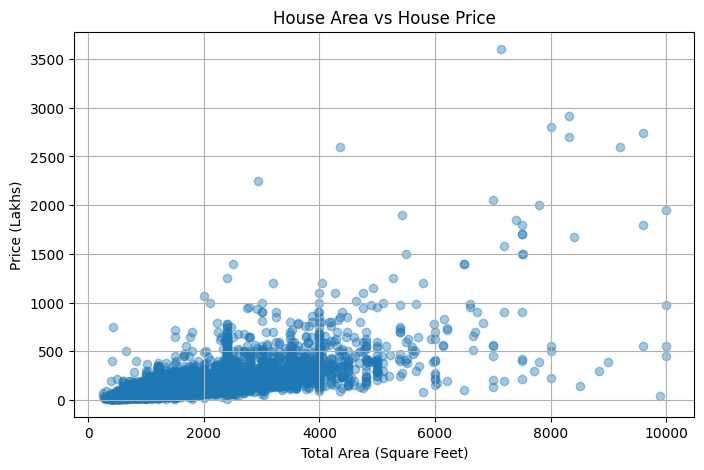

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean['total_sqft_clean'],
    df_clean['price'],
    alpha=0.4
)

plt.title('House Area vs House Price')
plt.xlabel('Total Area (Square Feet)')
plt.ylabel('Price (Lakhs)')
plt.grid(True)

plt.show()

### Observation – Scatter Plot

The scatter plot between total house area and house price shows a generally positive relationship. As the area of a house increases, its price tends to increase. Most data points are concentrated in the lower area and price ranges, while some properties show unusually high prices. The scattered distribution indicates that house area is related to price, but other factors may also influence property prices.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (10194, 1)
Testing features: (2549, 1)
Training target: (10194,)
Testing target: (2549,)


In [ ]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

print("\nLinear Regression Equation:")
print(f"Price = {model.intercept_:.2f} + ({model.coef_[0]:.4f} × Area)")

Intercept: -64.58164326655353
Coefficient: 0.11536650910302396

Linear Regression Equation:
Price = -64.58 + (0.1154 × Area)


In [ ]:
# Predict house prices for test data
y_pred = model.predict(X_test)

print("Predictions completed successfully!")
print("Number of predictions:", len(y_pred))

Predictions completed successfully!
Number of predictions: 2549


In [ ]:
comparison = pd.DataFrame({
    'Actual Price (Lakhs)': y_test.values,
    'Predicted Price (Lakhs)': y_pred
})

display(comparison.head(10))

,Actual Price (Lakhs),Predicted Price (Lakhs)
0,65.00,60.014187
1,31.48,61.167852
2,149.00,73.858168
3,31.05,54.822694
4,46.00,56.553191
5,50.19,80.203326
6,56.00,91.163144
7,25.25,-5.744724
8,50.00,58.860521
9,120.00,154.268625


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Metrics")
print("----------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Metrics
----------------------
MAE: 47.15060468338641
MSE: 10541.929379726804
RMSE: 102.6738982396539
R2 Score: 0.5113242110086605


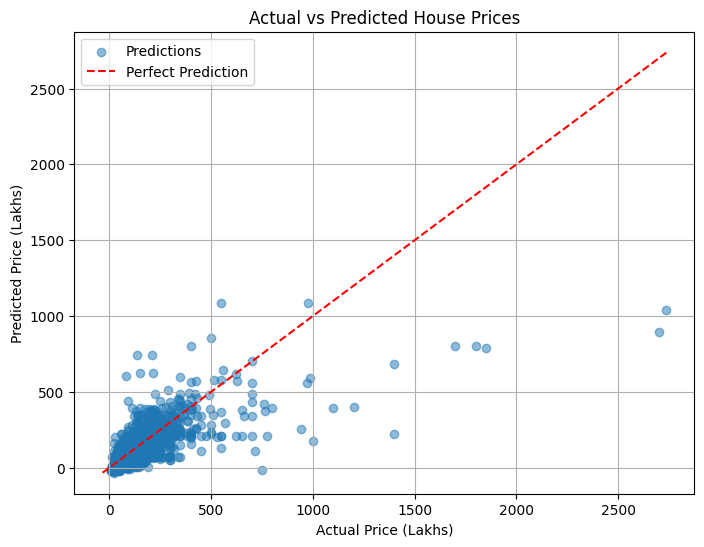

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5, label='Predictions')

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Price (Lakhs)')
plt.ylabel('Predicted Price (Lakhs)')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Predict price for a new house

new_house = pd.DataFrame({
    'total_sqft_clean': [1500]
})

new_prediction = model.predict(new_house)

print("House Area:", 1500, "sq. ft.")
print("Predicted Price:", round(new_prediction[0], 2), "Lakhs")
print("Predicted Price in Rupees:", round(new_prediction[0] * 100000, 2))

House Area: 1500 sq. ft.
Predicted Price: 108.47 Lakhs
Predicted Price in Rupees: 10846812.04


## Conclusion

In this activity, a Simple Linear Regression model was developed to predict Bengaluru house prices using total house area as the input feature. The dataset was inspected, cleaned, and prepared for machine learning. Extreme area values and duplicate records were removed. The data was divided into training and testing sets using an 80:20 ratio.

The model was trained and evaluated using MAE, MSE, RMSE, and R² Score. The R² score was 0.5113, indicating that the model explains approximately 51.13% of the variation in house prices. The visualizations showed a positive relationship between house area and price, but prediction errors were relatively large.

The activity demonstrated the complete workflow of a basic machine learning regression task, from data preparation to training, evaluation, visualization, and prediction. Model performance could be improved by including additional features such as location, number of bedrooms, property type, and amenities.